In [6]:
import re
import nltk
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords
from nltk.probability import FreqDist

# Download required NLTK datasets (run once)
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')

# Original 5-sentence paragraph
text = (
    "Space exploration has rapidly evolved from government-led missions into a thriving commercial industry. "
    "Modern reusable rockets significantly reduce launch costs, enabling frequent satellite deployments and deep-space research. "
    "Engineers are designing autonomous rovers to search for biosignatures beneath the Martian surface. "
    "Meanwhile, advanced orbital telescopes capture high-resolution images of distant exoplanets and galaxies. "
    "These technological breakthroughs inspire students and scientists worldwide to push the boundaries of human knowledge."
)

# 1. Convert text to lowercase and remove punctuation using re
lower_text = text.lower()
clean_text = re.sub(r'[^\w\s]', '', lower_text)

# 2. Tokenize text into sentences (from original/lowercase text) and words (from cleaned text)
sentences = sent_tokenize(lower_text)
words = word_tokenize(clean_text)

# 3. Compare Python's split() vs NLTK's word_tokenize() on raw lowercase text
raw_split_tokens = lower_text.split()
nltk_raw_tokens = word_tokenize(lower_text)

# 4. Remove stopwords using NLTK's stopwords list
stop_words = set(stopwords.words('english'))
filtered_words = [word for word in words if word not in stop_words]

# 5. Display word frequency distribution (excluding stopwords)
freq_dist = FreqDist(filtered_words)

print("Sentences:", sentences)
print("\nRaw split() sample:", raw_split_tokens[:15])
print("Raw word_tokenize() sample:", nltk_raw_tokens[:15])
print("\nFiltered Words (no punctuation/stopwords):", filtered_words)
print("\nWord Frequency Distribution:")
for word, count in freq_dist.most_common():
    print(f"{word}: {count}")

Sentences: ['space exploration has rapidly evolved from government-led missions into a thriving commercial industry.', 'modern reusable rockets significantly reduce launch costs, enabling frequent satellite deployments and deep-space research.', 'engineers are designing autonomous rovers to search for biosignatures beneath the martian surface.', 'meanwhile, advanced orbital telescopes capture high-resolution images of distant exoplanets and galaxies.', 'these technological breakthroughs inspire students and scientists worldwide to push the boundaries of human knowledge.']

Raw split() sample: ['space', 'exploration', 'has', 'rapidly', 'evolved', 'from', 'government-led', 'missions', 'into', 'a', 'thriving', 'commercial', 'industry.', 'modern', 'reusable']
Raw word_tokenize() sample: ['space', 'exploration', 'has', 'rapidly', 'evolved', 'from', 'government-led', 'missions', 'into', 'a', 'thriving', 'commercial', 'industry', '.', 'modern']

Filtered Words (no punctuation/stopwords): ['sp

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [7]:
import re
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer

nltk.download('wordnet')
nltk.download('omw-1.4')

# 1. Extract all words with only alphabets using re.findall()
alpha_words = re.findall(r'\b[a-zA-Z]+\b', text.lower())

# 2. Remove stop words using NLTK's stopword list
stop_words = set(stopwords.words('english'))
filtered_alpha = [w for w in alpha_words if w not in stop_words]

# 3 & 4. Perform stemming (PorterStemmer) and lemmatization (WordNetLemmatizer)
porter = PorterStemmer()
lemmatizer = WordNetLemmatizer()

print(f"{'Original Word':<18} {'Porter Stem':<18} {'WordNet Lemma':<18}")
print("-" * 54)
for word in dict.fromkeys(filtered_alpha):  # preserve order without duplicates
    print(f"{word:<18} {porter.stem(word):<18} {lemmatizer.lemmatize(word):<18}")

[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...


Original Word      Porter Stem        WordNet Lemma     
------------------------------------------------------
space              space              space             
exploration        explor             exploration       
rapidly            rapidli            rapidly           
evolved            evolv              evolved           
government         govern             government        
led                led                led               
missions           mission            mission           
thriving           thrive             thriving          
commercial         commerci           commercial        
industry           industri           industry          
modern             modern             modern            
reusable           reusabl            reusable          
rockets            rocket             rocket            
significantly      significantli      significantly     
reduce             reduc              reduce            
launch             launch        

[nltk_data]   Package omw-1.4 is already up-to-date!


In [8]:
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

# 3 short texts
docs = [
    "Quantum computing uses quantum qubits to solve complex optimization problems faster than classical computers.",
    "Neural networks and deep learning algorithms detect fraudulent financial transactions in real time.",
    "Cloud computing platforms deliver scalable cloud storage and distributed resources for enterprise applications."
]

# 1. Bag of Words representation using CountVectorizer
count_vec = CountVectorizer(stop_words='english')
bow_matrix = count_vec.fit_transform(docs)
bow_df = pd.DataFrame(
    bow_matrix.toarray(),
    columns=count_vec.get_feature_names_out(),
    index=["Text 1", "Text 2", "Text 3"]
)
print("Bag of Words Matrix:\n", bow_df)

# 2. Compute TF-IDF scores using TfidfVectorizer
tfidf_vec = TfidfVectorizer(stop_words='english')
tfidf_matrix = tfidf_vec.fit_transform(docs)
feature_names = np.array(tfidf_vec.get_feature_names_out())

# 3. Print top 3 keywords from each text using TF-IDF
print("\nTop 3 Keywords per Text (TF-IDF):")
for idx in range(len(docs)):
    scores = tfidf_matrix[idx].toarray().flatten()
    top_3_idx = scores.argsort()[::-1][:3]
    top_keywords = [(feature_names[i], round(float(scores[i]), 4)) for i in top_3_idx]
    print(f"Text {idx + 1}: {top_keywords}")

Bag of Words Matrix:
         algorithms  applications  classical  cloud  complex  computers  \
Text 1           0             0          1      0        1          1   
Text 2           1             0          0      0        0          0   
Text 3           0             1          0      2        0          0   

        computing  deep  deliver  detect  ...  quantum  qubits  real  \
Text 1          1     0        0       0  ...        2       1     0   
Text 2          0     1        0       1  ...        0       0     1   
Text 3          1     0        1       0  ...        0       0     0   

        resources  scalable  solve  storage  time  transactions  uses  
Text 1          0         0      1        0     0             0     1  
Text 2          0         0      0        0     1             1     0  
Text 3          1         1      0        1     0             0     0  

[3 rows x 31 columns]

Top 3 Keywords per Text (TF-IDF):
Text 1: [('quantum', 0.5428), ('solve', 0.2714

In [9]:
import re
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

ai_text = (
    "Artificial intelligence enables machines to learn patterns from massive datasets and make autonomous predictions. "
    "Deep neural networks power computer vision, natural language processing, and speech recognition systems across industries. "
    "Modern AI models rely on high-performance GPUs and continuous data pipelines to improve accuracy over time. "
    "Organizations deploy intelligent automation to optimize healthcare diagnostics, financial forecasting, and customer support."
)

blockchain_text = (
    "Blockchain is a decentralized distributed ledger technology that records transactions securely across peer-to-peer networks. "
    "Cryptographic hashing and consensus mechanisms ensure data immutability and transparency without relying on central authorities. "
    "Smart contracts automatically execute predefined agreements on decentralized platforms for supply chain and financial applications. "
    "Organizations adopt blockchain systems to enhance auditability, prevent tampering, and establish trust across digital ecosystems."
)

# 1. Preprocess and tokenize both texts
def preprocess_tokens(text):
    cleaned = re.sub(r'[^a-zA-Z\s]', '', text.lower())
    return cleaned.split()

tokens_ai = preprocess_tokens(ai_text)
tokens_bc = preprocess_tokens(blockchain_text)

# 2a. Jaccard Similarity using sets
set_ai, set_bc = set(tokens_ai), set(tokens_bc)
jaccard_sim = len(set_ai & set_bc) / len(set_ai | set_bc)

# 2b. Cosine Similarity using TfidfVectorizer + cosine_similarity()
tfidf = TfidfVectorizer(stop_words='english')
tfidf_vectors = tfidf.fit_transform([ai_text, blockchain_text])
cos_sim = cosine_similarity(tfidf_vectors[0:1], tfidf_vectors[1:2])[0][0]

print(f"Shared Vocabulary: {set_ai & set_bc}")
print(f"Jaccard Similarity: {jaccard_sim:.4f}")
print(f"Cosine Similarity:  {cos_sim:.4f}")

Shared Vocabulary: {'organizations', 'and', 'data', 'to', 'across', 'on', 'networks', 'systems', 'financial'}
Jaccard Similarity: 0.0938
Cosine Similarity:  0.0533


Sentiment  Polarity   Subjectivity   Review
-------------------------------------------------------------------------------------
Positive   0.250      0.600          The wireless noise-canceling headphones deliver crystal-clear audio, deep bass, and incredible battery life.
Positive   0.200      0.300          Customer support resolved my billing issue within minutes and the technician was very polite and helpful.
Neutral    0.000      0.000          The delivery arrived on Tuesday afternoon in a standard cardboard box.
Negative   -1.000     1.000          Terrible build quality; the charging port broke after two days and the app keeps crashing.
Positive   0.367      0.567          Absolutely love this ergonomic mechanical keyboard—typing feels smooth, fast, and effortless every day.


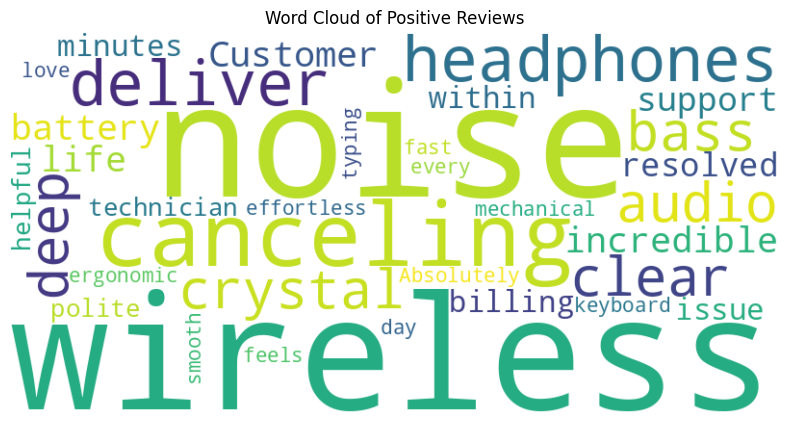

In [10]:
from textblob import TextBlob
from wordcloud import WordCloud
import matplotlib.pyplot as plt

# Sample product/service reviews
reviews = [
    "The wireless noise-canceling headphones deliver crystal-clear audio, deep bass, and incredible battery life.",
    "Customer support resolved my billing issue within minutes and the technician was very polite and helpful.",
    "The delivery arrived on Tuesday afternoon in a standard cardboard box.",
    "Terrible build quality; the charging port broke after two days and the app keeps crashing.",
    "Absolutely love this ergonomic mechanical keyboard—typing feels smooth, fast, and effortless every day."
]

positive_reviews = []

# 1 & 2. Compute polarity & subjectivity and classify into Positive / Negative / Neutral
print(f"{'Sentiment':<10} {'Polarity':<10} {'Subjectivity':<14} {'Review'}")
print("-" * 85)

for review in reviews:
    blob = TextBlob(review)
    polarity = blob.sentiment.polarity
    subjectivity = blob.sentiment.subjectivity

    if polarity > 0.1:
        sentiment = "Positive"
        positive_reviews.append(review)
    elif polarity < -0.1:
        sentiment = "Negative"
    else:
        sentiment = "Neutral"

    print(f"{sentiment:<10} {polarity:<10.3f} {subjectivity:<14.3f} {review}")

# 3. Create a word cloud for all positive reviews
positive_corpus = " ".join(positive_reviews)
wordcloud = WordCloud(
    width=800,
    height=400,
    background_color='white',
    colormap='viridis'
).generate(positive_corpus)

plt.figure(figsize=(10, 5))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title("Word Cloud of Positive Reviews")
plt.show()

In [11]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense
from tensorflow.keras.preprocessing.sequence import pad_sequences

try:
    from keras.preprocessing.text import Tokenizer
except ImportError:
    from tensorflow.keras.preprocessing.text import Tokenizer

# Training paragraph (~100 words)
corpus = """
Artificial intelligence is reshaping modern software engineering and scientific research across the globe.
Machine learning models analyze vast datasets to uncover hidden patterns and automate complex decisions.
Neural networks learn hierarchical representations from images, audio, and natural language text.
Researchers design deep architectures that improve accuracy in medical diagnosis and climate modeling.
Developers integrate intelligent APIs into everyday applications to assist users with writing and coding.
As computing hardware becomes faster, training larger language models becomes increasingly accessible.
Responsible engineering ensures these systems remain transparent, reliable, and beneficial for humanity.
Continuous innovation drives cognitive computing toward smarter and more adaptable solutions every year.
"""

# 1. Tokenize text using Tokenizer()
tokenizer = Tokenizer()
tokenizer.fit_on_texts([corpus])
total_words = len(tokenizer.word_index) + 1

# 2. Create n-gram input sequences
input_sequences = []
for line in corpus.strip().split("\n"):
    token_list = tokenizer.texts_to_sequences([line])[0]
    for i in range(1, len(token_list)):
        n_gram_seq = token_list[:i + 1]
        input_sequences.append(n_gram_seq)

max_seq_len = max(len(seq) for seq in input_sequences)
input_sequences = np.array(pad_sequences(input_sequences, maxlen=max_seq_len, padding='pre'))

X = input_sequences[:, :-1]
y = tf.keras.utils.to_categorical(input_sequences[:, -1], num_classes=total_words)

# Build a simple LSTM model
model = Sequential([
    Embedding(total_words, 32, input_length=max_seq_len - 1),
    LSTM(64),
    Dense(total_words, activation='softmax')
])

model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])

# 3. Train the model
model.fit(X, y, epochs=250, verbose=0)

# Generate 3 new lines starting from seed words
def generate_line(seed_text, next_words=8):
    output_text = seed_text
    for _ in range(next_words):
        token_list = tokenizer.texts_to_sequences([output_text])[0]
        token_list = pad_sequences([token_list], maxlen=max_seq_len - 1, padding='pre')
        predicted_probs = model.predict(token_list, verbose=0)
        predicted_index = np.argmax(predicted_probs, axis=-1)[0]
        output_word = tokenizer.index_word.get(predicted_index, "")
        if not output_word:
            break
        output_text += " " + output_word
    return output_text

seed_words = ["Artificial", "Machine", "Neural"]
print("Generated Lines:")
for seed in seed_words:
    print("-", generate_line(seed, next_words=7))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Generated Lines:
- Artificial intelligence is reshaping modern software engineering and
- Machine learning models analyze vast datasets to uncover
- Neural networks learn hierarchical representations from images audio
